# Practical Assignment 5

Name: Parth Nandkishor Shingane

PRN: 202401040210

Roll no:51

Div:A

Batch: A2

Github link: 

## Title
### Ensemble Learning and Performance Evaluation -> Predicting income level on the Adult (Census Income) data with Stacking, AdaBoost and Voting


## Aim
To build three kinds of ensemble classifiers - stacking, AdaBoost and voting - on the Adult Income dataset, and to find out, using proper classification metrics, whether they actually do better than the single models they are built from.

## Experiment Objectives
1. Build a **stacking ensemble** where a meta-classifier learns to combine the outputs of several base classifiers.
2. Build an **AdaBoost ensemble** with suitable weak base classifiers.
3. Build a **voting ensemble** that combines base classifiers by majority vote (and, for comparison, by averaging probabilities).
4. Compare every ensemble with the individual base models using accuracy, precision, recall, F1, ROC-AUC, PR-AUC and MCC, plus cross-validation.
5. Write down what we found, when each ensemble method is worth using, and what could be improved.

## Experiment Outcomes
By the end of this experiment we should be able to
* choose base models sensibly and apply stacking, boosting and voting without data leakage (**CO1, CO2**);
* pick metrics that make sense for an imbalanced, real-world problem instead of relying on accuracy alone (**CO1, CO2**);
* compare models critically and say whether a difference is real or just noise (**CO3, CO4**);
* discuss limitations, fairness and ethical concerns of the final model (**CO3, CO4**).

## Conceptual Background

A model's error has three parts: bias (it is too simple), variance (it is too sensitive to the training sample) and noise (nothing can fix this). An ensemble tries to reduce the first two by combining several models. It only works when the members are **reasonably accurate** and **make different mistakes**; ten copies of the same model add nothing.

**Voting.** Every base model is trained independently. In *hard* voting each model casts one vote and the majority class wins. In *soft* voting we average the predicted probabilities and take the class with the highest average, so confident models count for more. Voting mostly reduces variance.

**Stacking.** The base models (level 0) are trained first. Their predicted probabilities become the input features of a second model, the *meta-classifier* (level 1), which learns how much to trust each base model. To stop the meta-classifier from simply learning to trust whichever model memorised the training data, the base predictions it trains on are **out-of-fold** (produced by cross-validation).

**AdaBoost.** Weak learners (usually very shallow trees) are trained one after another. After round *t* the learner's weighted error ε<sub>t</sub> gives it a say α<sub>t</sub> = ½ ln((1 − ε<sub>t</sub>)/ε<sub>t</sub>), and the samples it got wrong are given more weight so the next learner concentrates on them. The final prediction is the sign of Σ α<sub>t</sub>·h<sub>t</sub>(x). Boosting mainly reduces bias, but because it keeps pushing on hard samples it can be hurt by noisy labels.

**Metrics.** Positive class here is *income > 50K* (the minority, about 24%). Because of that imbalance, accuracy is flattering: always predicting "<=50K" already scores about 76%. So we also look at precision, recall, F1, balanced accuracy, ROC-AUC, PR-AUC (area under the precision–recall curve, more honest under imbalance) and MCC.

## Flowchart of the Experiment

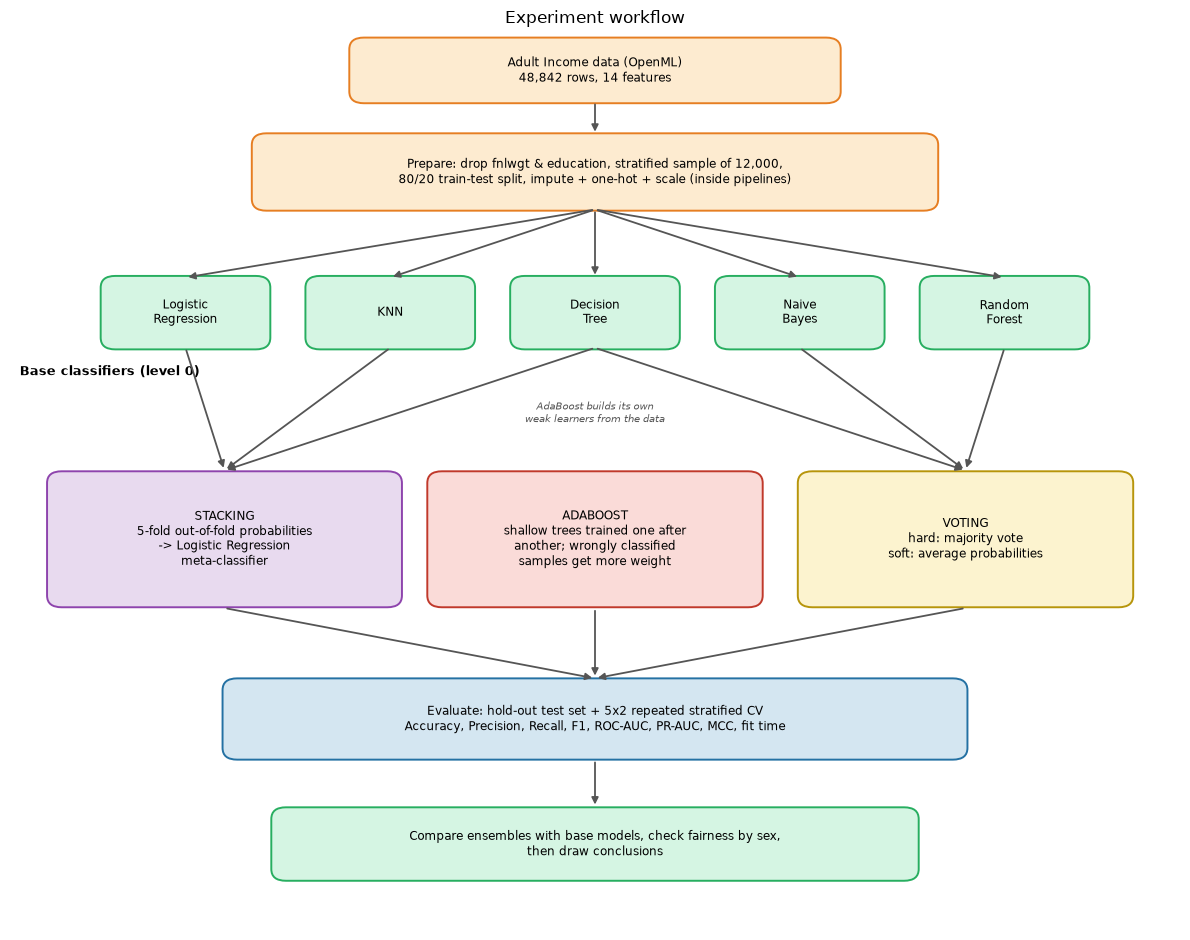

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

def box(ax, x, y, w, h, text, fc="#d6eaf8", ec="#2e86c1", fs=8.5):
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle="round,pad=0.02,rounding_size=0.15",
                                fc=fc, ec=ec, lw=1.4))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs)

def arrow(ax, p, q):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color="#555", lw=1.3))

fig, ax = plt.subplots(figsize=(12, 9.5)); ax.set_xlim(0, 12); ax.set_ylim(0, 11.5); ax.axis("off")
box(ax, 6, 11.0, 5.0, 0.8, "Adult Income data (OpenML)\n48,842 rows, 14 features", "#fdebd0", "#e67e22")
box(ax, 6, 9.7, 7.0, 0.95, "Prepare: drop fnlwgt & education, stratified sample of 12,000,\n80/20 train-test split, impute + one-hot + scale (inside pipelines)", "#fdebd0", "#e67e22")
arrow(ax, (6, 10.6), (6, 10.18))
names = ["Logistic\nRegression", "KNN", "Decision\nTree", "Naive\nBayes", "Random\nForest"]
xs = [1.8, 3.9, 6.0, 8.1, 10.2]
for x, n in zip(xs, names):
    box(ax, x, 7.9, 1.7, 0.9, n, "#d5f5e3", "#27ae60")
    arrow(ax, (6, 9.22), (x, 8.35))
ax.text(0.1, 7.1, "Base classifiers (level 0)", fontsize=9, fontweight="bold")
box(ax, 2.2, 5.0, 3.6, 1.7, "STACKING\n5-fold out-of-fold probabilities\n-> Logistic Regression\nmeta-classifier", "#e8daef", "#8e44ad")
box(ax, 6.0, 5.0, 3.4, 1.7, "ADABOOST\nshallow trees trained one after\nanother; wrongly classified\nsamples get more weight", "#fadbd8", "#c0392b")
box(ax, 9.8, 5.0, 3.4, 1.7, "VOTING\nhard: majority vote\nsoft: average probabilities", "#fcf3cf", "#b7950b")
for x in (1.8, 3.9, 6.0): arrow(ax, (x, 7.45), (2.2, 5.88))
for x in (6.0, 8.1, 10.2): arrow(ax, (x, 7.45), (9.8, 5.88))
ax.text(6.0, 6.5, "AdaBoost builds its own\nweak learners from the data", fontsize=7.5, ha="center", style="italic", color="#555")
box(ax, 6, 2.7, 7.6, 1.0, "Evaluate: hold-out test set + 5x2 repeated stratified CV\nAccuracy, Precision, Recall, F1, ROC-AUC, PR-AUC, MCC, fit time", "#d4e6f1", "#2471a3")
for x in (2.2, 6.0, 9.8): arrow(ax, (x, 4.12), (6, 3.22))
box(ax, 6, 1.1, 6.6, 0.9, "Compare ensembles with base models, check fairness by sex,\nthen draw conclusions", "#d5f5e3", "#27ae60")
arrow(ax, (6, 2.18), (6, 1.57))
plt.title("Experiment workflow", fontsize=12); plt.tight_layout(); plt.show()

# Code Implementation

## 1. Imports and loading the data

In [2]:
import warnings; warnings.filterwarnings("ignore")
import time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import (StackingClassifier, AdaBoostClassifier,
                              VotingClassifier, RandomForestClassifier)
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, matthews_corrcoef,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             precision_recall_curve, classification_report)

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
adult = fetch_openml("adult", version=2, as_frame=True, parser="auto")
X_full = adult.data.copy()
y_full = (adult.target == ">50K").astype(int)       # 1 = earns more than 50K, 0 = 50K or less

print("Rows, columns :", X_full.shape)
print("Share earning >50K: %.1f%%" % (100 * y_full.mean()))
miss = X_full.isna().sum()
print("\nColumns with missing values:\n", miss[miss > 0].to_string())
X_full.head()

Rows, columns : (48842, 14)
Share earning >50K: 23.9%

Columns with missing values:
 workclass         2799
occupation        2809
native-country     857


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States


## 2. A quick look at the data

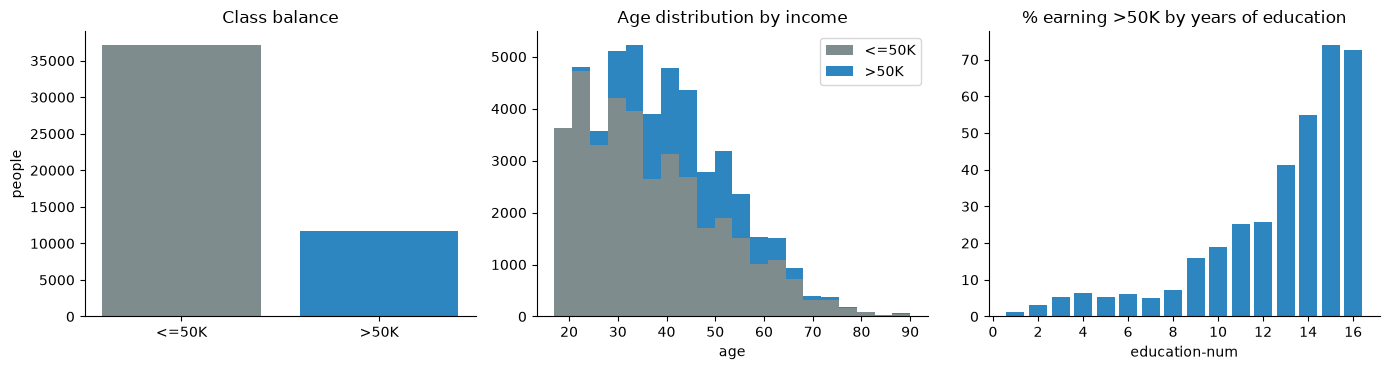

class   <=50K   >50K
sex                 
Female  0.891  0.109
Male    0.696  0.304


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))

ax[0].bar(["<=50K", ">50K"], y_full.value_counts().sort_index().values, color=["#7f8c8d", "#2e86c1"])
ax[0].set_title("Class balance"); ax[0].set_ylabel("people")

ax[1].hist([X_full.loc[y_full == 0, "age"], X_full.loc[y_full == 1, "age"]], bins=20,
           stacked=True, color=["#7f8c8d", "#2e86c1"], label=["<=50K", ">50K"])
ax[1].set_title("Age distribution by income"); ax[1].set_xlabel("age"); ax[1].legend()

rate = y_full.groupby(X_full["education-num"]).mean() * 100
ax[2].bar(rate.index, rate.values, color="#2e86c1")
ax[2].set_title("% earning >50K by years of education"); ax[2].set_xlabel("education-num")
plt.tight_layout(); plt.show()

print(pd.crosstab(X_full["sex"], y_full, normalize="index").round(3).rename(columns={0: "<=50K", 1: ">50K"}))

**What we notice:** roughly three out of four people earn 50K or less, so the classes are clearly imbalanced. Income rises with years of education, and very young people almost never fall in the high-income group. There is also a large gap between men and women in the raw data: about 30% of men but only about 11% of women are in the >50K class. This is a feature of the (1994 US census) data, not something a model should be proud of learning, and we come back to it in section 12.

## 3. Preparing the data

Some decisions we made, and why:

* **`fnlwgt` dropped** – it is a census sampling weight, not a property of the person.
* **`education` dropped** – it is the same information as `education-num`, just spelt out.
* **Missing values** (`workclass`, `occupation`, `native-country`) are all categorical, so we fill them with the most common value *inside the pipeline*. That way the fill value is learned from training data only.
* **Sample of 12,000 rows** – the full 48,842 rows would make stacking (many models × 5 inner folds) and repeated cross-validation painfully slow. The sample is stratified, so the class ratio is unchanged, and every model sees exactly the same data.
* Scaling and one-hot encoding sit inside a `ColumnTransformer` that is part of every model's pipeline, so nothing from the test set leaks into training.

In [5]:
X_full = X_full.drop(columns=["fnlwgt", "education"])

# stratified sample of 12,000 rows (same class ratio as the full data)
X_s, _, y_s, _ = train_test_split(X_full, y_full, train_size=12000, stratify=y_full, random_state=SEED)

X_train, X_test, y_train, y_test = train_test_split(X_s, y_s, test_size=0.20, stratify=y_s, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Positive rate -> train: %.3f, test: %.3f" % (y_train.mean(), y_test.mean()))

num_cols = X_s.select_dtypes(include="number").columns.tolist()
cat_cols = X_s.select_dtypes(exclude="number").columns.tolist()
print("Numeric:", num_cols); print("Categorical:", cat_cols)

def make_prep():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                              OneHotEncoder(handle_unknown="ignore", sparse_output=False)), cat_cols),
    ])

Train: (9600, 12) | Test: (2400, 12)
Positive rate -> train: 0.239, test: 0.239
Numeric: ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical: ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


## 4. Base classifiers

We want members from different families so that their errors are not all the same:

| Model | Why it is in the pool |
|---|---|
| Logistic Regression | linear and stable, usually a strong baseline on tabular data |
| KNN (k = 15) | decides locally from similar people |
| Decision Tree (depth 8) | non-linear rules, but high variance |
| Gaussian Naive Bayes | probabilistic with a (wrong but useful) independence assumption |
| Random Forest (200 trees) | already an ensemble (bagging) – a strong member to see how much more stacking/voting can add |

In [6]:
def base_models():
    return {
        "Logistic Regression": make_pipeline(make_prep(), LogisticRegression(max_iter=2000, random_state=SEED)),
        "KNN":                 make_pipeline(make_prep(), KNeighborsClassifier(n_neighbors=15)),
        "Decision Tree":       make_pipeline(make_prep(), DecisionTreeClassifier(max_depth=8, random_state=SEED)),
        "Naive Bayes":         make_pipeline(make_prep(), GaussianNB()),
        "Random Forest":       make_pipeline(make_prep(), RandomForestClassifier(n_estimators=200, min_samples_leaf=3,
                                                                                random_state=SEED)),
    }
base_names = list(base_models().keys())

results, preds, scores = {}, {}, {}

def evaluate(name, model):
    # fit on the training set, then record test-set metrics, predictions and scores
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_s = time.perf_counter() - t0
    pred = model.predict(X_test)
    if hasattr(model, "predict_proba"):
        score = model.predict_proba(X_test)[:, 1]
    else:                                   # hard voting has no probabilities: use the share of votes for ">50K"
        score = model.transform(X_test).mean(axis=1)
    results[name] = {
        "Accuracy":     accuracy_score(y_test, pred),
        "Balanced Acc": balanced_accuracy_score(y_test, pred),
        "Precision":    precision_score(y_test, pred),
        "Recall":       recall_score(y_test, pred),
        "F1":           f1_score(y_test, pred),
        "ROC-AUC":      roc_auc_score(y_test, score),
        "PR-AUC":       average_precision_score(y_test, score),
        "MCC":          matthews_corrcoef(y_test, pred),
        "Fit time (s)": fit_s,
    }
    preds[name], scores[name] = pred, score

for n, m in base_models().items():
    evaluate(n, m)

print("Baseline for reference: always predicting '<=50K' gives accuracy %.3f" % (1 - y_test.mean()))
pd.DataFrame(results).T.round(4)

Baseline for reference: always predicting '<=50K' gives accuracy 0.761


,Accuracy,Balanced Acc,Precision,Recall,F1,ROC-AUC,PR-AUC,MCC,Fit time (s)
Logistic Regression,0.8467,0.7523,0.7289,0.5714,0.6406,0.8963,0.7477,0.5515,0.0966
KNN,0.8283,0.7367,0.6680,0.5610,0.6098,0.8754,0.6891,0.5040,0.0272
Decision Tree,0.8492,0.7480,0.7500,0.5540,0.6373,0.8829,0.7113,0.5547,0.0687
Naive Bayes,0.4221,0.6107,0.2893,0.9721,0.4459,0.6728,0.3283,0.2377,0.0398
Random Forest,0.8562,0.7580,0.7694,0.5697,0.6547,0.9056,0.7796,0.5766,1.1119


**Reading the table.** Random Forest is the best single model (accuracy 0.856, F1 0.655, ROC-AUC 0.906), with Logistic Regression and the Decision Tree close behind. The always-"<=50K" baseline is 0.761, so these models are better than guessing, but not by a huge margin, and recall on the >50K class is only about 0.55–0.57 for all of them.

The odd one out is **Naive Bayes**: accuracy 0.42, which is *worse* than the do-nothing baseline, with recall 0.97 and precision 0.29. It labels almost everyone as a high earner. The reason is that Gaussian Naive Bayes assumes every feature is a bell curve and independent of the others; after one-hot encoding we are feeding it 0/1 columns, many of which are strongly dependent (for example `marital-status` and `relationship`), so its probabilities become extremely over-confident. We deliberately kept it in the pool instead of quietly swapping it out, because a weak or badly calibrated member is exactly the situation where we can see how each ensemble method copes.

## 5. Stacking ensemble

All five base models are used as level-0 learners. A Logistic Regression is the meta-classifier: it is simple, cannot overfit much on five input columns, and its coefficients tell us directly how much each base model is trusted. `cv=5` makes the base predictions fed to the meta-classifier out-of-fold.

Meta-classifier coefficients (one per base model's P(>50K)):
Logistic Regression    0.101
KNN                    0.504
Decision Tree          1.347
Naive Bayes            0.691
Random Forest          5.330


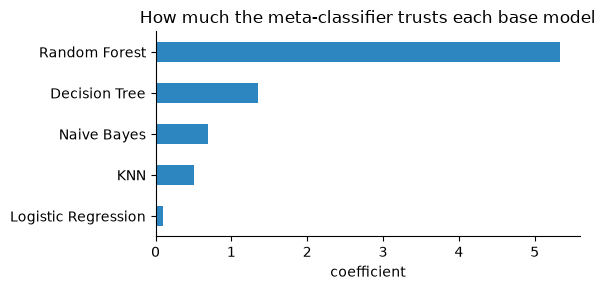

In [7]:
stack = StackingClassifier(
    estimators=list(base_models().items()),
    final_estimator=LogisticRegression(max_iter=2000, random_state=SEED),
    stack_method="predict_proba", cv=5)
evaluate("Stacking (LR meta)", stack)

coefs = pd.Series(stack.final_estimator_.coef_[0], index=base_names)
print("Meta-classifier coefficients (one per base model's P(>50K)):")
print(coefs.round(3).to_string())
coefs.sort_values().plot.barh(color="#2e86c1", figsize=(6, 3), title="How much the meta-classifier trusts each base model")
plt.xlabel("coefficient"); plt.tight_layout(); plt.show()

In [8]:
# Does the choice of meta-classifier matter? Try two other options.
for label, final in {"Stacking (Random Forest meta)": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED),
                     "Stacking (Decision Tree meta)": DecisionTreeClassifier(max_depth=4, random_state=SEED)}.items():
    evaluate(label, StackingClassifier(estimators=list(base_models().items()), final_estimator=final,
                                       stack_method="predict_proba", cv=5))
pd.DataFrame(results).T.loc[["Stacking (LR meta)", "Stacking (Random Forest meta)", "Stacking (Decision Tree meta)"]].round(4)

,Accuracy,Balanced Acc,Precision,Recall,F1,ROC-AUC,PR-AUC,MCC,Fit time (s)
Stacking (LR meta),0.8558,0.7685,0.7468,0.6010,0.6660,0.9068,0.7797,0.5810,7.4184
Stacking (Random Forest meta),0.8575,0.7702,0.7522,0.6028,0.6692,0.9021,0.7714,0.5856,8.8720
Stacking (Decision Tree meta),0.8571,0.7603,0.7692,0.5749,0.6580,0.9034,0.7550,0.5797,7.3439


**Reading the output.** The meta-classifier gives by far the biggest weight to the Random Forest (coefficient 5.3), then the Decision Tree (1.3), Naive Bayes (0.7) and KNN (0.5); Logistic Regression gets almost none (0.1), probably because its information is already contained in the other, correlated inputs. So the meta-learner mostly learned "trust the forest, use the others to adjust".

Stacking (LR meta) improves recall to 0.601 (Random Forest alone: 0.570) and F1 to 0.666 (vs 0.655), while accuracy (0.856) and ROC-AUC (0.907) are essentially the same as the forest's. The choice of meta-classifier barely matters here (F1 between 0.658 and 0.669), which is a sign that the gain is limited by what the base models know, not by how cleverly they are combined. The price is training time: about 7 s against about 1 s for the forest.

## 6. AdaBoost ensemble

A decision stump (a tree with one split) is the textbook weak learner, so we start there. We also try slightly deeper trees (depth 2 and 3), because a stump can only look at one feature at a time and income depends on combinations like age, education and marital status.

In [9]:
def ada(depth, n, lr):
    return make_pipeline(make_prep(), AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=depth, random_state=SEED),
        n_estimators=n, learning_rate=lr, random_state=SEED))

ada_cfgs = {
    "AdaBoost (stump, 200)":   ada(1, 200, 1.0),
    "AdaBoost (depth-2, 150)": ada(2, 150, 0.5),
    "AdaBoost (depth-3, 100)": ada(3, 100, 0.5),
}
for n, m in ada_cfgs.items():
    evaluate(n, m)
pd.DataFrame(results).T.loc[list(ada_cfgs)].round(4)

,Accuracy,Balanced Acc,Precision,Recall,F1,ROC-AUC,PR-AUC,MCC,Fit time (s)
"AdaBoost (stump, 200)",0.8571,0.7562,0.7783,0.5627,0.6532,0.8994,0.7708,0.5779,1.8706
"AdaBoost (depth-2, 150)",0.8512,0.7410,0.7775,0.5296,0.6301,0.9006,0.7639,0.5567,1.9651
"AdaBoost (depth-3, 100)",0.8554,0.7461,0.7918,0.5366,0.6397,0.9026,0.7755,0.5698,1.8248


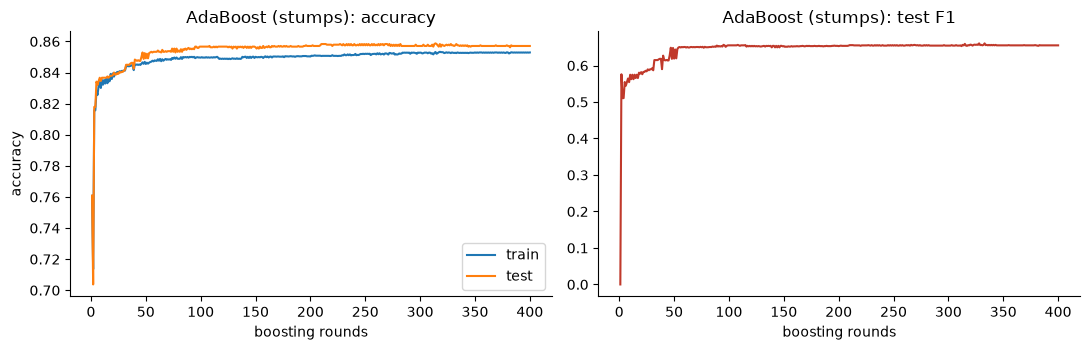

Test accuracy after 50 / 100 / 200 / 400 rounds: [0.8492, 0.8567, 0.8571, 0.8571]


In [10]:
# How does performance change with the number of boosting rounds? staged_* gives every round from one fit.
prep_tmp = make_prep()
Xtr_t, Xte_t = prep_tmp.fit_transform(X_train), prep_tmp.transform(X_test)
booster = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, random_state=SEED),
                             n_estimators=400, learning_rate=1.0, random_state=SEED).fit(Xtr_t, y_train)
tr_acc = [accuracy_score(y_train, p) for p in booster.staged_predict(Xtr_t)]
te_acc = [accuracy_score(y_test, p)  for p in booster.staged_predict(Xte_t)]
te_f1  = [f1_score(y_test, p)        for p in booster.staged_predict(Xte_t)]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(range(1, 401), tr_acc, label="train"); ax[0].plot(range(1, 401), te_acc, label="test")
ax[0].set_xlabel("boosting rounds"); ax[0].set_ylabel("accuracy"); ax[0].set_title("AdaBoost (stumps): accuracy"); ax[0].legend()
ax[1].plot(range(1, 401), te_f1, color="#c0392b"); ax[1].set_xlabel("boosting rounds"); ax[1].set_title("AdaBoost (stumps): test F1")
plt.tight_layout(); plt.show()
print("Test accuracy after 50 / 100 / 200 / 400 rounds:", [round(te_acc[i - 1], 4) for i in (50, 100, 200, 400)])

**Reading the output.** AdaBoost with 200 stumps gets accuracy 0.857, F1 0.653 and ROC-AUC 0.899, which puts it level with the Random Forest on accuracy and a bit below the stacked model on recall. Deeper trees did not help: depth-3 has a slightly better ROC-AUC (0.903) but a lower F1 (0.640), because it becomes more cautious (precision 0.79, recall only 0.54).

The rounds plot shows that test accuracy goes 0.849 → 0.857 between 50 and 100 rounds and then stays at 0.857 up to 400 rounds, so more than about 100 rounds buys nothing. (We picked 200 for the stump model from this flat region, not by searching for the best test point.) With the default 0.5 threshold, AdaBoost leans towards the majority class: high precision, modest recall. This is a threshold effect we revisit in the conclusion.

## 7. Voting ensemble

Both versions use the same five base models. *Hard* voting is the plain majority vote the assignment asks for; *soft* voting averages probabilities.

In [11]:
evaluate("Voting (hard)", VotingClassifier(list(base_models().items()), voting="hard"))
evaluate("Voting (soft)", VotingClassifier(list(base_models().items()), voting="soft"))
pd.DataFrame(results).T.loc[["Voting (hard)", "Voting (soft)"]].round(4)

,Accuracy,Balanced Acc,Precision,Recall,F1,ROC-AUC,PR-AUC,MCC,Fit time (s)
Voting (hard),0.8517,0.7663,0.7300,0.6028,0.6603,0.8356,0.6290,0.5708,1.3235
Voting (soft),0.8325,0.7878,0.6356,0.7021,0.6672,0.9007,0.7682,0.5569,1.3445


In [12]:
# Sanity check: rebuild the hard vote by hand from the already fitted base-model predictions.
votes = np.column_stack([preds[n] for n in base_names])
by_hand = (votes.sum(axis=1) >= 3).astype(int)               # at least 3 of the 5 models say ">50K"
print("Hand-made majority vote identical to VotingClassifier(hard):", bool((by_hand == preds["Voting (hard)"]).all()))
split = (votes.min(axis=1) != votes.max(axis=1)).sum()
print("Test samples where the five base models do not all agree: %d of %d (%.1f%%)" % (split, len(y_test), 100 * split / len(y_test)))

Hand-made majority vote identical to VotingClassifier(hard): True
Test samples where the five base models do not all agree: 1647 of 2400 (68.6%)


**Reading the output.** The two voting rules behave quite differently on this dataset. Hard voting (accuracy 0.852, F1 0.660) is basically a safe average: Naive Bayes's wrong votes are simply out-voted by the other four models. Soft voting has the best F1 of all (0.667) and the best balanced accuracy (0.788), but its accuracy drops to 0.833, the lowest of any ensemble, and precision falls to 0.636. The explanation is the Naive Bayes problem from section 4: its probabilities are extreme, so when they are averaged with the others they drag the result towards ">50K". Soft voting therefore catches more high earners (recall 0.702) at the cost of many more false alarms. The "score" for hard voting is only the share of votes (six possible values), so its ROC-AUC (0.836) is not comparable with the others.

Naive Bayes is also the reason the five models "disagree" on 68.6% of the test samples; between the other four the disagreement is much lower (section 11).

# Result

## 8. Hold-out test results

In [13]:
main = base_names + ["Stacking (LR meta)", "AdaBoost (stump, 200)", "AdaBoost (depth-3, 100)",
                     "Voting (hard)", "Voting (soft)"]
kind = lambda n: "Base" if n in base_names else "Ensemble"
res = pd.DataFrame(results).T.loc[main]
res.insert(0, "Type", [kind(n) for n in res.index])
display(res.sort_values("F1", ascending=False).round(4))

,Type,Accuracy,Balanced Acc,Precision,Recall,F1,ROC-AUC,PR-AUC,MCC,Fit time (s)
Voting (soft),Ensemble,0.8325,0.7878,0.6356,0.7021,0.6672,0.9007,0.7682,0.5569,1.3445
Stacking (LR meta),Ensemble,0.8558,0.7685,0.7468,0.6010,0.6660,0.9068,0.7797,0.5810,7.4184
Voting (hard),Ensemble,0.8517,0.7663,0.7300,0.6028,0.6603,0.8356,0.6290,0.5708,1.3235
Random Forest,Base,0.8562,0.7580,0.7694,0.5697,0.6547,0.9056,0.7796,0.5766,1.1119
"AdaBoost (stump, 200)",Ensemble,0.8571,0.7562,0.7783,0.5627,0.6532,0.8994,0.7708,0.5779,1.8706
Logistic Regression,Base,0.8467,0.7523,0.7289,0.5714,0.6406,0.8963,0.7477,0.5515,0.0966
"AdaBoost (depth-3, 100)",Ensemble,0.8554,0.7461,0.7918,0.5366,0.6397,0.9026,0.7755,0.5698,1.8248
Decision Tree,Base,0.8492,0.7480,0.7500,0.5540,0.6373,0.8829,0.7113,0.5547,0.0687
KNN,Base,0.8283,0.7367,0.6680,0.5610,0.6098,0.8754,0.6891,0.5040,0.0272
Naive Bayes,Base,0.4221,0.6107,0.2893,0.9721,0.4459,0.6728,0.3283,0.2377,0.0398


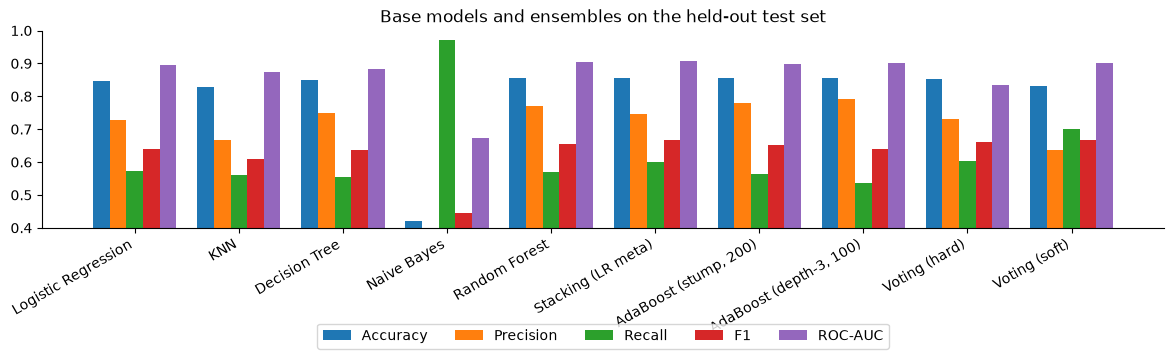

In [14]:
metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
fig, ax = plt.subplots(figsize=(12, 4.3))
x = np.arange(len(main)); w = 0.16
for i, mt in enumerate(metrics):
    ax.bar(x + (i - 2) * w, res[mt], w, label=mt)
ax.set_xticks(x); ax.set_xticklabels(main, rotation=30, ha="right")
ax.set_ylim(0.4, 1.0); ax.set_title("Base models and ensembles on the held-out test set")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.45))
plt.tight_layout(); plt.show()

**What the test set says.** Looking at accuracy alone, almost all models sit between 0.83 and 0.86, so the ranking would look like a tie. The more informative metrics separate them: the three best by F1 are the two voting ensembles and stacking (0.660–0.667), while the best single model, Random Forest, has 0.655 and the strongest AdaBoost 0.653. For ROC-AUC and PR-AUC, stacking (0.907 / 0.780) and Random Forest (0.906 / 0.780) are practically identical. So on the test set the ensembles are a little better in F1/recall and not better in ranking quality. With only 574 positive test cases, differences of one or two hundredths should not be over-interpreted, which is why we do cross-validation next.

## 9. Repeated cross-validation

The test set has 2,400 people, and only about 570 of them earn more than 50K, so a single split can easily mislead. We repeat 5-fold cross-validation twice (10 scores per model) on the whole 12,000-row sample and look at the mean and spread. Hard voting is left out of the ROC-AUC and PR-AUC columns because it produces no probabilities.

In [15]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
cv_models = {**base_models(),
    "Stacking (LR meta)": StackingClassifier(estimators=list(base_models().items()),
                              final_estimator=LogisticRegression(max_iter=2000), stack_method="predict_proba", cv=5),
    "AdaBoost (stump, 200)": ada(1, 200, 1.0),
    "AdaBoost (depth-3, 100)": ada(3, 100, 0.5),
    "Voting (hard)": VotingClassifier(list(base_models().items()), voting="hard"),
    "Voting (soft)": VotingClassifier(list(base_models().items()), voting="soft"),
}
scoring = {"accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc", "average_precision": "average_precision"}
rows, raw_acc, raw_f1 = {}, {}, {}
for n, m in cv_models.items():
    sc = {k: v for k, v in scoring.items() if not (n == "Voting (hard)" and k in ("roc_auc", "average_precision"))}
    out = cross_validate(m, X_s, y_s, cv=cv, scoring=sc)
    raw_acc[n], raw_f1[n] = out["test_accuracy"], out["test_f1"]
    rows[n] = {k: (f"{out['test_'+k].mean():.4f} +/- {out['test_'+k].std():.4f}" if k in sc else "n/a") for k in scoring}
    rows[n]["_f1"] = out["test_f1"].mean()
cv_df = pd.DataFrame(rows).T.sort_values("_f1", ascending=False).drop(columns="_f1")
cv_df.columns = ["Accuracy", "F1", "ROC-AUC", "PR-AUC"]
cv_df.insert(0, "Type", [kind(n) for n in cv_df.index])
display(cv_df)

,Type,Accuracy,F1,ROC-AUC,PR-AUC
Voting (soft),Ensemble,0.8424 +/- 0.0075,0.6892 +/- 0.0137,0.9054 +/- 0.0066,0.7739 +/- 0.0169
Stacking (LR meta),Ensemble,0.8560 +/- 0.0061,0.6671 +/- 0.0144,0.9101 +/- 0.0060,0.7847 +/- 0.0156
Voting (hard),Ensemble,0.8526 +/- 0.0058,0.6663 +/- 0.0149,n/a,n/a
Random Forest,Base,0.8576 +/- 0.0060,0.6584 +/- 0.0162,0.9109 +/- 0.0052,0.7829 +/- 0.0144
"AdaBoost (stump, 200)",Ensemble,0.8526 +/- 0.0059,0.6508 +/- 0.0183,0.9066 +/- 0.0060,0.7718 +/- 0.0131
"AdaBoost (depth-3, 100)",Ensemble,0.8524 +/- 0.0052,0.6461 +/- 0.0168,0.9079 +/- 0.0054,0.7776 +/- 0.0131
Decision Tree,Base,0.8428 +/- 0.0059,0.6422 +/- 0.0212,0.8872 +/- 0.0067,0.7064 +/- 0.0131
Logistic Regression,Base,0.8424 +/- 0.0061,0.6343 +/- 0.0155,0.8999 +/- 0.0065,0.7481 +/- 0.0159
KNN,Base,0.8370 +/- 0.0068,0.6320 +/- 0.0150,0.8862 +/- 0.0055,0.7008 +/- 0.0166
Naive Bayes,Base,0.4086 +/- 0.0484,0.4408 +/- 0.0204,0.6822 +/- 0.0220,0.3360 +/- 0.0162


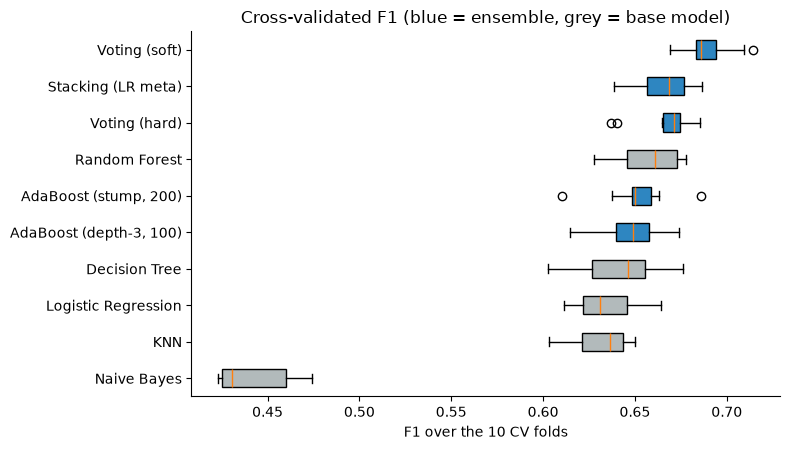

In [16]:
order = sorted(raw_f1, key=lambda k: np.mean(raw_f1[k]))
fig, ax = plt.subplots(figsize=(8, 4.6))
bp = ax.boxplot([raw_f1[k] for k in order], vert=False, patch_artist=True)
ax.set_yticklabels(order)
for patch, k in zip(bp["boxes"], order):
    patch.set_facecolor("#2e86c1" if k not in base_names else "#b2babb")
ax.set_xlabel("F1 over the 10 CV folds"); ax.set_title("Cross-validated F1 (blue = ensemble, grey = base model)")
plt.tight_layout(); plt.show()

**What cross-validation adds.** Ranked by F1, soft voting is first (0.689 ± 0.014), then stacking (0.667) and hard voting (0.666), then Random Forest (0.658) and AdaBoost (0.646–0.651); Logistic Regression, Decision Tree and KNN are at 0.63–0.64 and Naive Bayes at 0.44. For accuracy, ROC-AUC and PR-AUC the picture is different: Random Forest (0.858 / 0.911 / 0.783) and stacking (0.856 / 0.910 / 0.785) are tied at the top, with differences far smaller than the fold-to-fold spread (about 0.006 for accuracy and AUC, 0.015 for F1).

Two honest conclusions follow. (1) Stacking is *as good as* the best single model, not clearly better; its biggest benefit is that it is not worse than the forest while also using the other models. (2) Soft voting's F1 lead (about +0.03 over the forest) is roughly two standard deviations, but its ROC-AUC is *lower* than the forest's. That means it does not rank people better; it just uses a more generous decision threshold. This would show up for any model if we simply lowered the threshold, so the lead should not be read as "soft voting is the better model". (The repeated-CV folds overlap, so the standard deviations are only a rough guide.)

## 10. ROC curves, precision-recall curves and confusion matrices

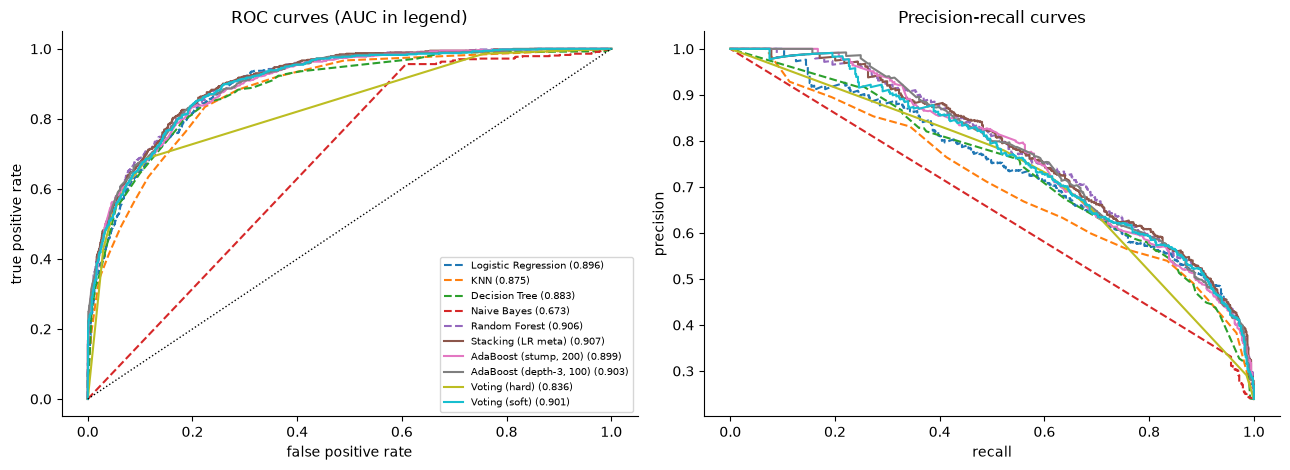

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for n in main:
    ls = "-" if kind(n) == "Ensemble" else "--"
    fpr, tpr, _ = roc_curve(y_test, scores[n]); ax[0].plot(fpr, tpr, ls, label="%s (%.3f)" % (n, results[n]["ROC-AUC"]))
    pr, rc, _ = precision_recall_curve(y_test, scores[n]); ax[1].plot(rc, pr, ls)
ax[0].plot([0, 1], [0, 1], "k:", lw=1); ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate")
ax[0].set_title("ROC curves (AUC in legend)"); ax[0].legend(fontsize=7, loc="lower right")
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title("Precision-recall curves")
plt.tight_layout(); plt.show()

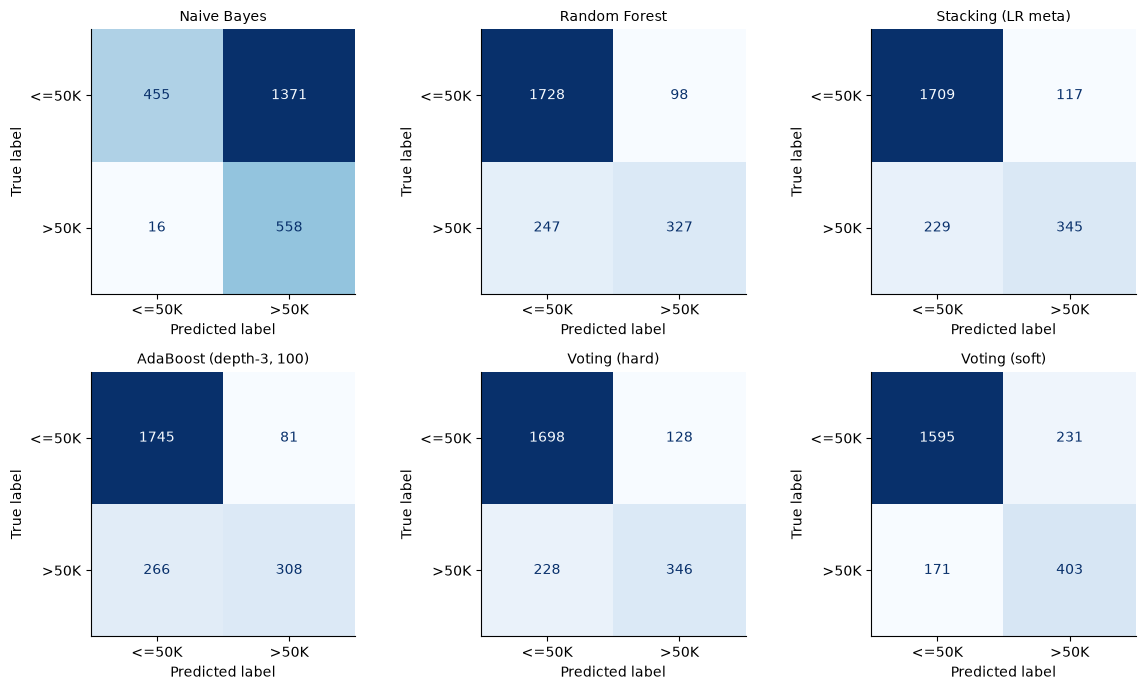

In [18]:
show = ["Naive Bayes", "Random Forest", "Stacking (LR meta)", "AdaBoost (depth-3, 100)", "Voting (hard)", "Voting (soft)"]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for a, n in zip(axes.ravel(), show):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[n]), display_labels=["<=50K", ">50K"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(n, fontsize=10)
plt.tight_layout(); plt.show()

In [19]:
best_name = res[res.Type == "Ensemble"]["F1"].idxmax()
print("Best ensemble on test F1:", best_name, "\n")
print(classification_report(y_test, preds[best_name], target_names=["<=50K", ">50K"], digits=3))

Best ensemble on test F1: Voting (soft) 

              precision    recall  f1-score   support

       <=50K      0.903     0.873     0.888      1826
        >50K      0.636     0.702     0.667       574

    accuracy                          0.833      2400
   macro avg      0.769     0.788     0.778      2400
weighted avg      0.839     0.833     0.835      2400



**Curves and matrices.** In the ROC and precision-recall plots, the curves of stacking, Random Forest and the AdaBoost models lie almost on top of each other near the top, Logistic Regression is slightly below, and Naive Bayes is far below; the hard-voting curve is a few straight segments because it only has six possible scores. The confusion matrices tell the same story as the metrics: Naive Bayes marks most people as >50K, AdaBoost and the forest make few false alarms but miss many high earners, and soft voting sits at the other end, finding more of them but flagging more wrong ones. The classification report for soft voting (the best ensemble by test F1) shows the trade-off in numbers: precision 0.636 and recall 0.702 for the >50K class, against 0.903 and 0.873 for the majority class.

## 11. How different are the base models, really?

In [20]:
dis = pd.DataFrame({a: {b: (preds[a] != preds[b]).mean() for b in base_names} for a in base_names})
display(dis.round(3))
print("Average pairwise disagreement: %.3f" % dis.values[np.triu_indices(len(base_names), 1)].mean())
correct = (votes == y_test.values[:, None])
print("At least one base model correct (oracle upper bound): %.3f" % correct.any(axis=1).mean())
print("Best single model accuracy                         : %.3f" % max(results[n]["Accuracy"] for n in base_names))

,Logistic Regression,KNN,Decision Tree,Naive Bayes,Random Forest
Logistic Regression,0.000,0.080,0.065,0.622,0.058
KNN,0.080,0.000,0.100,0.609,0.075
Decision Tree,0.065,0.100,0.000,0.637,0.051
Naive Bayes,0.622,0.609,0.637,0.000,0.631
Random Forest,0.058,0.075,0.051,0.631,0.000


Average pairwise disagreement: 0.293
At least one base model correct (oracle upper bound): 0.974
Best single model accuracy                         : 0.856


**Why the gains are modest.** The average pairwise disagreement looks high (0.29), but that is almost entirely Naive Bayes, which disagrees with every other model on about 61–64% of the samples. Among Logistic Regression, KNN, Decision Tree and Random Forest the disagreement is only 5–10%: they are all looking at the same encoded features and make mostly the same mistakes. The oracle line shows how much room there is in principle — on 97.4% of the test samples at least one model is right, against 85.6% for the best single model — but a combiner cannot know *which* model is right on a given person, so it only captures a small part of that gap. In short, the ensembles are limited by the diversity of the pool more than by the way we combine it.

## 12. Cost of the ensembles and a fairness check

In [21]:
display(pd.DataFrame(results).T.loc[main, ["Fit time (s)", "F1"]].round(3).sort_values("Fit time (s)"))

,Fit time (s),F1
KNN,0.027,0.610
Naive Bayes,0.040,0.446
Decision Tree,0.069,0.637
Logistic Regression,0.097,0.641
Random Forest,1.112,0.655
Voting (hard),1.324,0.660
Voting (soft),1.345,0.667
"AdaBoost (depth-3, 100)",1.825,0.640
"AdaBoost (stump, 200)",1.871,0.653
Stacking (LR meta),7.418,0.666


In [22]:
# Does the model treat men and women similarly? (the data itself is skewed: see the crosstab in section 2)
sex_test = X_test["sex"].reset_index(drop=True)
yt = y_test.reset_index(drop=True)
rows = []
for n in ["Logistic Regression", "Random Forest", "Stacking (LR meta)", "AdaBoost (depth-3, 100)", "Voting (soft)"]:
    p = pd.Series(preds[n])
    for g in ["Female", "Male"]:
        m = (sex_test == g)
        rows.append({"Model": n, "Group": g, "Actual >50K rate": yt[m].mean(), "Predicted >50K rate": p[m].mean(),
                     "Recall": recall_score(yt[m], p[m]), "Precision": precision_score(yt[m], p[m])})
fair = pd.DataFrame(rows).round(3)
display(fair)

,Model,Group,Actual >50K rate,Predicted >50K rate,Recall,Precision
0,Logistic Regression,Female,0.115,0.072,0.505,0.807
1,Logistic Regression,Male,0.301,0.245,0.584,0.718
2,Random Forest,Female,0.115,0.054,0.374,0.791
3,Random Forest,Male,0.301,0.238,0.607,0.767
4,Stacking (LR meta),Female,0.115,0.060,0.407,0.771
5,Stacking (LR meta),Male,0.301,0.258,0.638,0.744
6,"AdaBoost (depth-3, 100)",Female,0.115,0.054,0.385,0.814
7,"AdaBoost (depth-3, 100)",Male,0.301,0.215,0.565,0.789
8,Voting (soft),Female,0.115,0.093,0.538,0.662
9,Voting (soft),Male,0.301,0.349,0.733,0.632


**What we see.** In this test set about 11.5% of women and 30.1% of men are in the >50K class. Every model under-predicts the high-income class for women (for example Random Forest predicts 5.4% for women against a true 11.5%) and the recall for women is lower than for men for every model.

The recall gap between men and women is smallest for plain Logistic Regression (0.505 vs 0.584, a gap of about 0.08) and larger for the models that score better overall: Random Forest 0.374 vs 0.607 (0.23), stacking 0.407 vs 0.638 (0.23), AdaBoost 0.385 vs 0.565 (0.18) and soft voting 0.538 vs 0.733 (0.20). So in our run the more powerful models were also the ones that treated the two groups most differently. Two cautions: the test set contains only about a hundred high-earning women, so these numbers are noisy, and we did not try any bias-mitigation technique, so this is a diagnostic rather than a solution. It is nevertheless a good reminder that a better F1 does not automatically mean a better model for the people affected.

# Conclusion

## What we did
We built a stacking ensemble (Logistic Regression meta-classifier), AdaBoost ensembles (stumps and shallow trees), and hard and soft voting ensembles on top of five base classifiers (Logistic Regression, KNN, Decision Tree, Naive Bayes and Random Forest) using a 12,000-person stratified sample of the Adult Income data. We compared everything on a hold-out test set and with 5×2 repeated cross-validation, using accuracy, precision, recall, F1, balanced accuracy, ROC-AUC, PR-AUC and MCC, and we looked at training time and at a fairness breakdown by sex.

## What we found
1. **On ranking quality and accuracy, no ensemble clearly beat the best single model.** Random Forest (accuracy 0.858, ROC-AUC 0.911 in CV) and stacking (0.856, 0.910) are statistically tied; AdaBoost and hard voting are within a few thousandths of them.
2. **On F1 and recall the ensembles helped a bit.** Stacking and hard voting improve F1 by about 0.01 and recall by about 0.03 over the forest; soft voting improves F1 by about 0.03, but only because it is more willing to predict ">50K" (its ROC-AUC is lower, not higher).
3. **Ensembles protect against a bad member.** Naive Bayes alone is worse than always predicting the majority class (accuracy 0.42). Stacking learned to give it a small weight, and hard voting outvoted it, so both stayed near the top. Soft voting, which averages probabilities, was pulled towards over-predicting the positive class.
4. **AdaBoost saturated early** (no gain after about 100 rounds) and, with the default threshold, favoured precision over recall.
5. **Cost:** stacking took about 7 s to train, against about 1 s for the forest and 0.2 s for logistic regression, for a gain that is within the noise on most metrics.
6. **The pool was not diverse enough.** Apart from Naive Bayes, the base models disagree with each other on only 5–10% of people.

## When to use which method

| Method | Use it when | Watch out for |
|---|---|---|
| **Stacking** | you have several different, individually decent models, enough data, and want the most reliable result; the meta-weights also tell you which model matters | training cost (every base model is refitted in every fold); needs out-of-fold predictions, otherwise it leaks |
| **AdaBoost** | the base learners are weak and the data is reasonably clean; you want a fast, compact model | label noise and outliers (they get up-weighted); stops improving after enough rounds; may need a lowered threshold when the positive class is rare |
| **Voting – hard** | you want a cheap, robust combination, especially when one or two members may be poor | gives no probabilities, so no meaningful ROC/PR curve; every member has an equal say |
| **Voting – soft** | all members give reasonably calibrated probabilities and you care about recall / balanced accuracy | one badly calibrated member (here Naive Bayes) can distort the average |

A practical rule from this experiment: first find the best single model with cross-validation. If it is already a strong ensemble itself (like a Random Forest), expect only small extra gains from stacking or voting, and spend the effort on features, the decision threshold and calibration instead.

## Limitations
* We used a 12,000-row sample (about a quarter of the data) and fixed hyper-parameters, so absolute numbers would change with the full data and with tuning.
* The decision threshold was left at 0.5 for every model although the classes are imbalanced; some of the differences in recall and F1 are really threshold effects.
* No statistical test was run; we relied on mean ± standard deviation over overlapping CV folds.
* Naive Bayes on one-hot data is a poor choice; a better-suited member (e.g. a categorical Naive Bayes or gradient boosting) would give a different picture.

## Future improvements
* Add more diverse members (gradient boosting such as LightGBM/XGBoost, an SVM or a small neural network) and drop redundant ones; measure diversity formally.
* Tune hyper-parameters with nested cross-validation, and tune the decision threshold (for example to maximise F1 or to hit a required recall) on validation data.
* Calibrate probabilities (Platt / isotonic) before soft voting and stacking.
* Use the full dataset and a significance test such as McNemar's test or a corrected resampled t-test.
* Try fairness-aware methods (re-weighting, threshold per group, or excluding sex and its proxies such as `relationship`) and report the trade-off with accuracy.

## Ethical and societal considerations
Predicting whether someone earns above a threshold looks harmless, but similar models are used in credit scoring, hiring and marketing. Our fairness check showed that all models under-identify high-income women more than men, and the more accurate models widened the gap. The data is from 1994 and reflects the labour market of that time, so using it to make decisions today would repeat old inequalities. Ensembles are also harder to explain than a single model, which matters when a person has a right to know why a decision was made. Finally, stacking and repeated cross-validation use much more computation than a simple model for a very small gain, which has an energy cost that should be justified.

## Final summary
Ensembles did what theory says they should only partly. They made the result *more robust* (a bad member did not ruin stacking or hard voting) and slightly improved recall and F1, but they did not beat a strong Random Forest in ranking quality, because the base models were too similar and the data's noise limits every model. The main lesson for us is that ensemble gains depend on the quality and diversity of the members, and that we should judge models by several metrics, by cross-validation and by who is affected by the errors, not by one accuracy number.